# Persona 2 — Clasificación de congestión (Corte 3)

**Proyecto:** Sistema inteligente para planificación de rutas y análisis de movilidad  
**Curso:** SIST5036 — Inteligencia Artificial  
**Enfoque:** ML supervisado (clasificación multiclasse)

### Entregables de esta notebook
1. Definición de categorías de congestión (`baja`, `media`, `alta`)
2. Dataset compartido (aristas OSM × horas sintéticas)
3. Comparación de modelos supervisados
4. Matrices de confusión y métricas de desempeño

> La congestión de entrenamiento es **sintética** (perfil horario del Corte 2 + geometría OSM). No es tráfico medido en vivo.

## 1. Setup

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
BACKEND = ROOT / "backend"
sys.path.insert(0, str(BACKEND))

from src.ml.categorias import CATEGORIAS_CONGESTION, descripcion_categorias
from src.ml.clasificacion import entrenar_y_comparar, matriz_a_dataframe
from src.ml.dataset import (
    FEATURES_NUMERICAS,
    TARGET,
    cargar_grafo_osm,
    construir_dataset_clasificacion,
    guardar_dataset,
    resumen_dataset,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
print("Backend:", BACKEND)

Backend: C:\Users\Jorgesinho\Documents\Repos\Proyecto_IA\backend


## 2. Categorías de congestión

Se reutilizan los umbrales del simulador horario (ADR-026):

| Categoría | Factor de ralentización |
|-----------|-------------------------|
| `baja` | &lt; 1.40 |
| `media` | [1.40, 2.00) |
| `alta` | ≥ 2.00 |

Las vías `bloqueada` **no** entran al modelo: son cierres explícitos, no un estado predicible por atributos de tráfico.

In [2]:
for clase, texto in descripcion_categorias().items():
    print(f"- {clase}: {texto}")
print("Orden canónico:", CATEGORIAS_CONGESTION)

- baja: Tráfico fluido: factor de ralentización < 1.40
- media: Tráfico moderado: factor en [1.40, 2.00)
- alta: Tráfico congestionado: factor ≥ 2.00
Orden canónico: ('baja', 'media', 'alta')


## 3. Dataset compartido

Cada fila = **una arista OSM** observada en **una hora** del perfil sintético.

**Features (entrada):** hora, intensidad del perfil, distancia, tiempo/velocidad base, carriles, sentido, incidentes, peso y tipo de vía.  
**Target:** `congestion` ∈ {baja, media, alta}.

In [3]:
csv_path = BACKEND / "datos" / "ml" / "dataset_clasificacion_congestion.csv"

if csv_path.exists():
    df = pd.read_csv(csv_path)
    print("Cargado CSV existente:", csv_path)
else:
    grafo = cargar_grafo_osm()
    df = construir_dataset_clasificacion(grafo)
    guardar_dataset(df, csv_path)
    print("Dataset generado:", csv_path)

resumen = resumen_dataset(df)
display(resumen)
display(df.head())
display(df[TARGET].value_counts().rename("conteo").to_frame())

Cargado CSV existente: C:\Users\Jorgesinho\Documents\Repos\Proyecto_IA\backend\datos\ml\dataset_clasificacion_congestion.csv


{'filas': 27856,
 'columnas': 15,
 'clases': {'media': 14772, 'baja': 10183, 'alta': 2901},
 'horas_unicas': 16,
 'aristas_unicas': 1741}

,arista_id,hora_salida,hora_decimal,intensidad_hora,distancia_m,tiempo_base_min,velocidad_base_kmh,carriles,sentido_unico,incidentes,peso_tipo_via,tipo_via,congestion,tiempo_simulado_min,velocidad_simulada_kmh
0,583975820,00:00,0.0,0.155,17.191568,0.020630,50.0,3.0,1,0.0,1.12,secundaria,baja,0.024340,42.379339
1,89615978,00:00,0.0,0.155,101.025944,0.121231,30.0,2.0,1,0.0,1.00,terciaria,baja,0.139079,26.150189
2,856959932,00:00,0.0,0.155,12.253162,0.014704,45.0,1.0,1,0.0,1.00,terciaria,baja,0.016662,39.710503
3,916471064,00:00,0.0,0.155,12.641424,0.015170,45.0,2.0,1,0.0,1.00,terciaria,baja,0.017629,38.722113
4,"[1074517252, 1074517255]",00:00,0.0,0.155,100.278989,0.120335,50.0,2.0,1,0.0,1.24,primaria,baja,0.140188,42.919191


,conteo
congestion,
media,14772
baja,10183
alta,2901


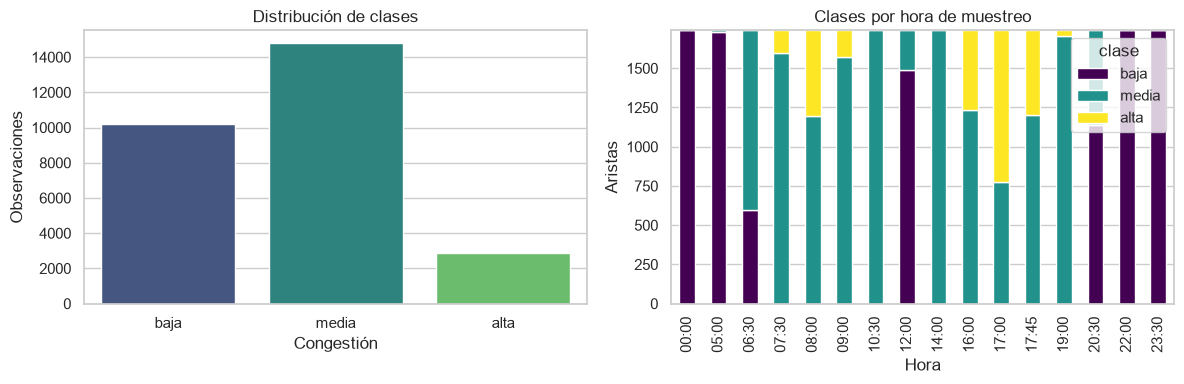

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

orden = list(CATEGORIAS_CONGESTION)
conteos = df[TARGET].value_counts().reindex(orden)
sns.barplot(x=conteos.index, y=conteos.values, ax=axes[0], hue=conteos.index, legend=False, palette="viridis")
axes[0].set_title("Distribución de clases")
axes[0].set_xlabel("Congestión")
axes[0].set_ylabel("Observaciones")

pivot = (
    df.groupby(["hora_salida", TARGET]).size().unstack(fill_value=0).reindex(columns=orden)
)
pivot.plot(kind="bar", stacked=True, ax=axes[1], colormap="viridis")
axes[1].set_title("Clases por hora de muestreo")
axes[1].set_xlabel("Hora")
axes[1].set_ylabel("Aristas")
axes[1].legend(title="clase", loc="upper right")
plt.tight_layout()
plt.show()

## 4. Entrenamiento y comparación de modelos

Hold-out estratificado 75/25 (semilla 42). Mismos features y preprocesado para todos:

- Regresión logística (multinomial, balanceada)
- Random Forest
- Gradient Boosting
- KNN (k=7)
- SVM lineal

In [5]:
print("Features numéricas:", FEATURES_NUMERICAS)
comparacion = entrenar_y_comparar(df)
tabla = comparacion.tabla_metricas()
print("Mejor modelo (F1 macro):", comparacion.mejor_modelo)
print("Hold-out:", comparacion.X_test_shape, "| clases test:", comparacion.y_test_counts)
display(tabla.style.format({
    "accuracy": "{:.4f}",
    "precision_macro": "{:.4f}",
    "recall_macro": "{:.4f}",
    "f1_macro": "{:.4f}",
}))

Features numéricas: ('hora_decimal', 'intensidad_hora', 'distancia_m', 'tiempo_base_min', 'velocidad_base_kmh', 'carriles', 'sentido_unico', 'incidentes', 'peso_tipo_via')


Mejor modelo (F1 macro): Gradient Boosting
Hold-out: (6964, 10) | clases test: {'baja': 2546, 'media': 3693, 'alta': 725}


,modelo,accuracy,precision_macro,recall_macro,f1_macro
0,Gradient Boosting,0.9380,0.9135,0.9058,0.9094
1,SVM lineal,0.9279,0.8840,0.9232,0.9008
2,Random Forest,0.9196,0.8648,0.9354,0.8908
3,KNN (k=7),0.9164,0.8831,0.8872,0.8851
4,Regresión logística,0.9126,0.8545,0.9412,0.8827


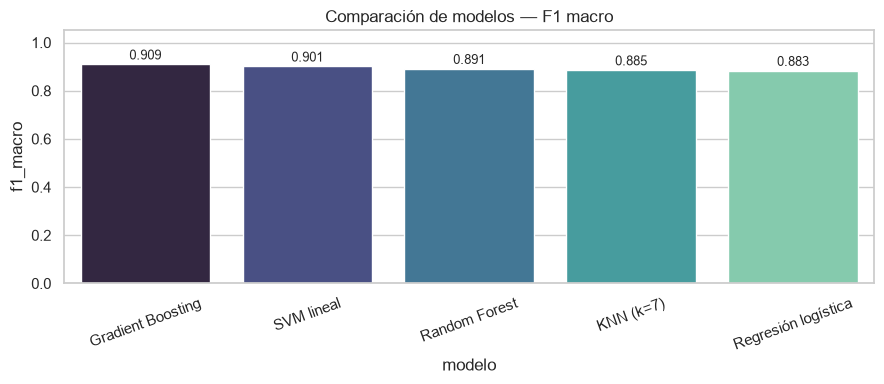

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=tabla, x="modelo", y="f1_macro", hue="modelo", legend=False, ax=ax, palette="mako")
ax.set_title("Comparación de modelos — F1 macro")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=20)
for i, v in enumerate(tabla["f1_macro"]):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## 5. Matrices de confusión

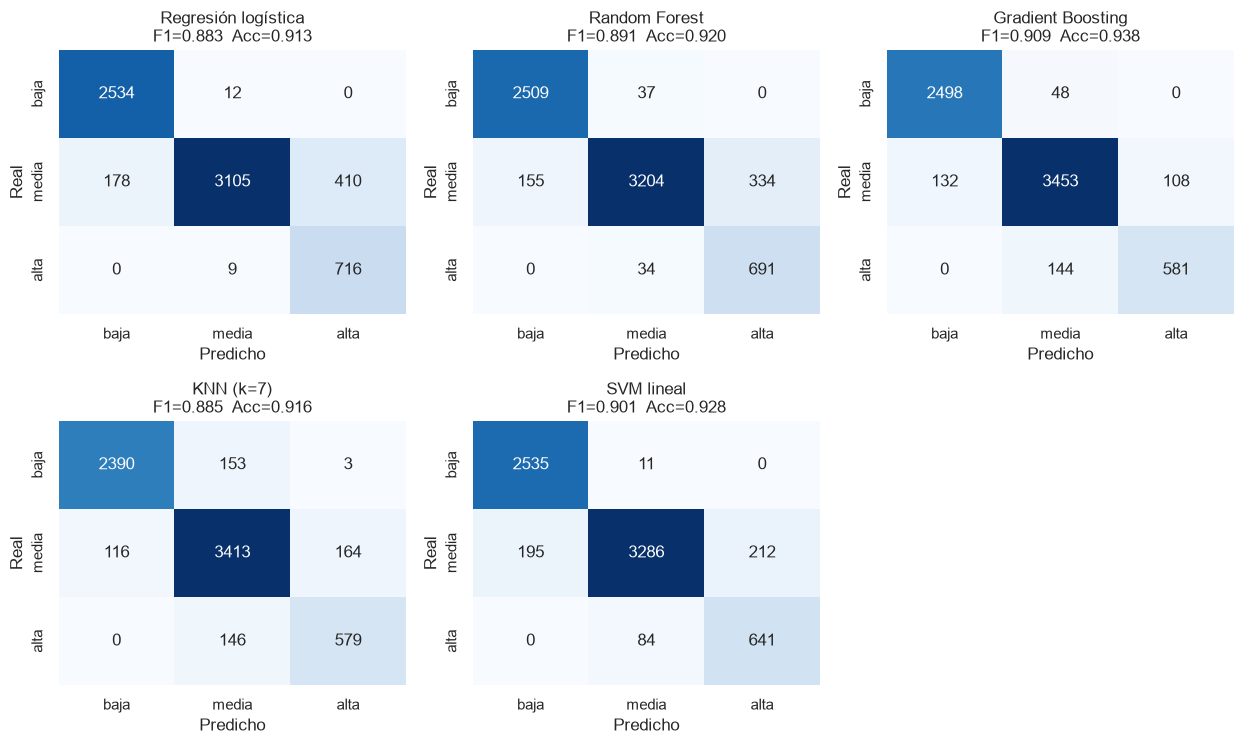

In [7]:
n = len(comparacion.resultados)
cols = 3
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.8 * rows))
axes = axes.flatten()

for ax, resultado in zip(axes, comparacion.resultados):
    cm = matriz_a_dataframe(resultado.matriz_confusion, comparacion.clases)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        cbar=False,
        xticklabels=list(comparacion.clases),
        yticklabels=list(comparacion.clases),
    )
    ax.set_title(f"{resultado.nombre}\nF1={resultado.f1_macro:.3f}  Acc={resultado.accuracy:.3f}")
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Reporte detallado del mejor modelo

In [8]:
mejor = next(r for r in comparacion.resultados if r.nombre == comparacion.mejor_modelo)
reporte_df = pd.DataFrame(mejor.reporte).T
display(reporte_df.style.format("{:.4f}", na_rep="-"))
print("Matriz de confusión (mejor modelo):")
display(matriz_a_dataframe(mejor.matriz_confusion, comparacion.clases))

,precision,recall,f1-score,support
baja,0.9498,0.9811,0.9652,2546.0000
media,0.9473,0.9350,0.9411,3693.0000
alta,0.8433,0.8014,0.8218,725.0000
accuracy,0.9380,0.9380,0.9380,0.9380
macro avg,0.9135,0.9058,0.9094,6964.0000
weighted avg,0.9374,0.9380,0.9375,6964.0000


Matriz de confusión (mejor modelo):


,pred_baja,pred_media,pred_alta
real_baja,2498,48,0
real_media,132,3453,108
real_alta,0,144,581


## 7. Conclusiones (Persona 2)

- Se definieron **3 categorías** alineadas con el simulador del proyecto.
- El dataset compartido permite que regresión/agrupamiento (otras personas) usen la misma fuente.
- Los modelos se comparan con **accuracy, precision/recall/F1 macro** y **matriz de confusión**.
- El mejor modelo según F1 macro queda identificado arriba; en datos sintéticos los árboles/boosting suelen capturar mejor interacciones hora × tipo de vía.
- Limitación: las etiquetas no son tráfico real; para producción harían falta velocidades observadas y validación empírica.

### Archivos generados
- `backend/datos/ml/dataset_clasificacion_congestion.csv`
- `backend/datos/ml/metricas_clasificacion.json` (vía script)
- Módulo reutilizable: `backend/src/ml/`